# Análise exploratória dos dados (EDA)

Projeto Integrador de Engenharia de Dados: previsão de churn em uma loja de artigos esportivos.

Este notebook lê tudo **do PostgreSQL**, depois que o pipeline (`python -m src.pipeline`) carregou as cinco fontes.
O objetivo é conhecer o dado antes de modelar: o que entrou, o que a limpeza removeu, como a loja vende e
o que diferencia o cliente que abandona do cliente que fica.

Sequência:
1. O que está no banco
2. Qualidade: do dado bruto ao dado limpo
3. Vendas ao longo do tempo
4. Produtos e categorias
5. Clientes
6. Localidade (API do IBGE e Kaggle)
7. Churn: quem abandona
8. Correlação das features com o churn
9. Achados

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))   # para importar o pacote src a partir da pasta notebooks/

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown

from src import config, features, load, transform
from src.graficos import AZUL, CINZA, LARANJA, TEXTO, configurar, limpar_eixos, rotular, salvar

configurar()
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_colwidth', 110)
pd.set_option('display.float_format', lambda v: f'{v:,.2f}')

engine = load.conectar()
ler = lambda sql: load.ler(engine, sql)
print('Banco:', engine.url.render_as_string(hide_password=True))

Banco: postgresql+psycopg2://localhost/projeto_integrador


## 1. O que está no banco

Três schemas: `staging` guarda cada fonte como chegou (tudo texto), `dw` guarda o dado limpo no modelo estrela
e `ml` guarda as features e os resultados do modelo.

In [2]:
tabelas = ler("""
    SELECT table_schema AS schema, table_name AS tabela, table_type AS tipo
    FROM information_schema.tables
    WHERE table_schema IN ('staging', 'dw', 'ml')
    ORDER BY array_position(ARRAY['staging', 'dw', 'ml'], table_schema::text), table_name
""")
tabelas['linhas'] = [ler(f'SELECT count(*) AS n FROM {s}.{t}')['n'][0] for s, t in zip(tabelas['schema'], tabelas['tabela'])]
tabelas

,schema,tabela,tipo,linhas
0,staging,cidades_kaggle,BASE TABLE,5573
1,staging,clientes,BASE TABLE,1545
2,staging,compras,BASE TABLE,17592
3,staging,municipios_ibge,BASE TABLE,5571
4,staging,produtos,BASE TABLE,25
5,dw,dim_cliente,BASE TABLE,1500
6,dw,dim_data,BASE TABLE,545
7,dw,dim_localidade,BASE TABLE,5571
8,dw,dim_produto,BASE TABLE,25
9,dw,etl_etapas,BASE TABLE,10


As chaves estrangeiras do modelo estrela, lidas do catálogo do PostgreSQL:

In [3]:
ler("""
    SELECT conrelid::regclass AS tabela, conname AS restricao, pg_get_constraintdef(oid) AS definicao
    FROM pg_constraint
    WHERE contype = 'f' AND connamespace = 'dw'::regnamespace
    ORDER BY 1, 2
""")

,tabela,restricao,definicao
0,dw.dim_cliente,dim_cliente_codigo_ibge_fkey,FOREIGN KEY (codigo_ibge) REFERENCES dw.dim_localidade(codigo_ibge)
1,dw.fato_compras,fato_compras_cliente_id_fkey,FOREIGN KEY (cliente_id) REFERENCES dw.dim_cliente(cliente_id)
2,dw.fato_compras,fato_compras_data_compra_fkey,FOREIGN KEY (data_compra) REFERENCES dw.dim_data(data)
3,dw.fato_compras,fato_compras_produto_id_fkey,FOREIGN KEY (produto_id) REFERENCES dw.dim_produto(produto_id)


## 2. Qualidade: do dado bruto ao dado limpo

O dado bruto de `staging` tem os problemas típicos de sistemas diferentes: valores ausentes, o mesmo texto
escrito de várias formas, datas em dois formatos e valores como texto.

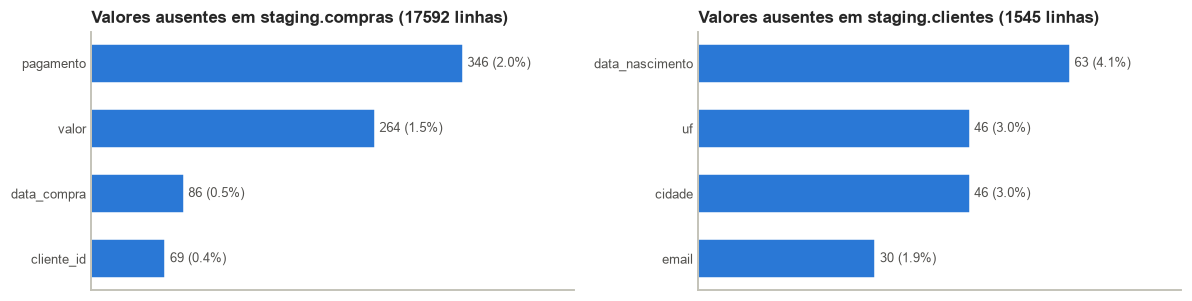

In [4]:
st_compras = ler('SELECT * FROM staging.compras')
st_clientes = ler('SELECT * FROM staging.clientes')

fig, eixos = plt.subplots(1, 2, figsize=(11, 2.9))
for ax, df, nome in [(eixos[0], st_compras, 'staging.compras'), (eixos[1], st_clientes, 'staging.clientes')]:
    nulos = df.isna().sum()
    nulos = nulos[nulos > 0].sort_values()
    barras = ax.barh(nulos.index, nulos.values, color=AZUL, height=0.6)
    rotular(ax, barras, labels=[f'{v} ({v / len(df):.1%})' for v in nulos.values])
    ax.set(title=f'Valores ausentes em {nome} ({len(df)} linhas)', xlim=(0, nulos.max() * 1.3))
    limpar_eixos(ax)
fig.tight_layout()
salvar(fig, '01_ausentes.png')

In [5]:
print('Grafias diferentes para o mesmo valor (staging -> dw):')
for tabela, coluna, limpa in [('staging.clientes', 'cidade', 'dw.dim_localidade l JOIN dw.dim_cliente c USING (codigo_ibge)'),
                              ('staging.clientes', 'segmento', 'dw.dim_cliente'), ('staging.compras', 'canal', 'dw.fato_compras')]:
    antes = ler(f'SELECT count(DISTINCT {coluna}) AS n FROM {tabela}')['n'][0]
    depois = ler(f"SELECT count(DISTINCT {'municipio' if coluna == 'cidade' else coluna}) AS n FROM {limpa}")['n'][0]
    print(f'  {coluna:9s} {antes:4d} -> {depois:3d}')
print('\nExemplos de segmento em staging:', sorted(st_clientes['segmento'].dropna().unique())[:12])
print('Datas de compra fora do padrão AAAA-MM-DD:', (~st_compras['data_compra'].str.fullmatch(r'\d{4}-\d{2}-\d{2}', na=False)).sum())
print('Valores escritos como texto (R$):', st_compras['valor'].str.contains('R', na=False).sum())

Grafias diferentes para o mesmo valor (staging -> dw):
  cidade     114 ->  30
  segmento    15 ->   3
  canal       17 ->   3

Exemplos de segmento em staging: ['  Bronze ', '  Ouro ', '  Prata ', 'BRONZE', 'Bronze', 'Bronze  ', 'OURO', 'Ouro', 'Ouro  ', 'PRATA', 'Prata', 'Prata  ']
Datas de compra fora do padrão AAAA-MM-DD: 1512
Valores escritos como texto (R$): 691


A tabela `dw.etl_etapas` é gravada pelo próprio ETL: cada etapa registra quantas linhas entraram, quantas removeu
e quantas restaram. É a trilha de auditoria da limpeza.

In [6]:
etapas = ler('SELECT fonte, etapa, entraram, removidos, restaram, descricao FROM dw.etl_etapas ORDER BY ordem')
etapas

,fonte,etapa,entraram,removidos,restaram,descricao
0,localidades,municípios do IBGE,5571,0,5571,Remove município sem UF ou região na resposta da API
1,localidades,indicadores do Kaggle,5571,0,5571,"Junção por nome + UF: 5551 municípios com IDHM, 20 ficam sem indicador"
2,produtos,catálogo válido,25,0,25,Achata o JSON e remove produto repetido ou sem preço e custo
3,clientes,sem duplicatas,1545,45,1500,Mantém uma linha por cliente_id (a mais completa)
4,clientes,sem inválidos,1500,0,1500,"Remove cliente sem id, nome, segmento ou data de cadastro válida"
5,clientes,município do IBGE,1500,0,1500,Troca cidade + UF pelo código do IBGE: 45 clientes sem cidade ficam com localidade nula
6,compras,sem duplicatas,17592,512,17080,Remove linhas repetidas
7,compras,sem inválidos,17080,732,16348,"Remove compra sem cliente, data ou valor, com data impossível ou futura, valor negativo ou quantidade fora..."
8,compras,integridade referencial,16348,99,16249,Remove compra de cliente fora do cadastro ou de produto fora do catálogo
9,compras,sem outliers de preço,16249,157,16092,Remove compra com preço unitário fora de 50% a 110% do preço de tabela


In [7]:
resumo = pd.DataFrame({
    'fonte': ['compras', 'clientes'],
    'linhas em staging': [len(st_compras), len(st_clientes)],
    'linhas no dw': [ler('SELECT count(*) AS n FROM dw.fato_compras')['n'][0], ler('SELECT count(*) AS n FROM dw.dim_cliente')['n'][0]],
})
resumo['aproveitamento'] = (resumo['linhas no dw'] / resumo['linhas em staging']).map('{:.1%}'.format)
resumo

,fonte,linhas em staging,linhas no dw,aproveitamento
0,compras,17592,16092,91.5%
1,clientes,1545,1500,97.1%


**Outliers.** Com o catálogo carregado, não é preciso estimar o que é um preço absurdo: o preço unitário de cada
compra é comparado com o preço de tabela do próprio produto. A loja vende de protetor bucal a estação de
musculação, então um limite único para a coluna `valor` trataria produto caro como erro.

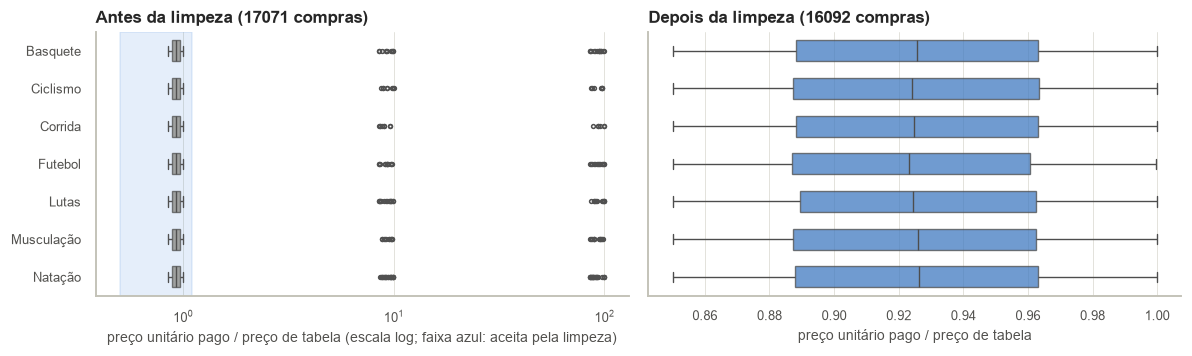

In [8]:
produtos = ler('SELECT produto_id, categoria, preco FROM dw.dim_produto')
bruto = st_compras.assign(valor=transform.para_numero(st_compras['valor']), quantidade=pd.to_numeric(st_compras['quantidade'], errors='coerce'),
                          produto_id=st_compras['produto_id'].str.strip().str.upper()).merge(produtos, on='produto_id')
bruto = bruto[(bruto['valor'] > 0) & bruto['quantidade'].between(1, 20)]
bruto['relacao'] = bruto['valor'] / bruto['quantidade'] / bruto['preco']
limpo = ler('SELECT f.valor / f.quantidade / p.preco AS relacao, p.categoria FROM dw.fato_compras f JOIN dw.dim_produto p USING (produto_id)')
ordem = sorted(produtos['categoria'].unique())

fig, eixos = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for ax, dados, cor, titulo in [(eixos[0], bruto, CINZA, f'Antes da limpeza ({len(bruto)} compras)'), (eixos[1], limpo, AZUL, f'Depois da limpeza ({len(limpo)} compras)')]:
    sns.boxplot(data=dados, x='relacao', y='categoria', order=ordem, ax=ax, color=cor, width=0.55, linewidth=0.9, fliersize=2.5, boxprops={'alpha': 0.75})
    ax.set(title=titulo, xlabel='preço unitário pago / preço de tabela', ylabel='')
eixos[0].set_xscale('log')
eixos[0].axvspan(transform.PRECO_MIN, transform.PRECO_MAX, color=AZUL, alpha=0.12)
eixos[0].set_xlabel('preço unitário pago / preço de tabela (escala log; faixa azul: aceita pela limpeza)')
fig.tight_layout()
salvar(fig, '02_outliers_preco.png')

## 3. Vendas ao longo do tempo

A agregação é feita no banco, usando a dimensão de data.

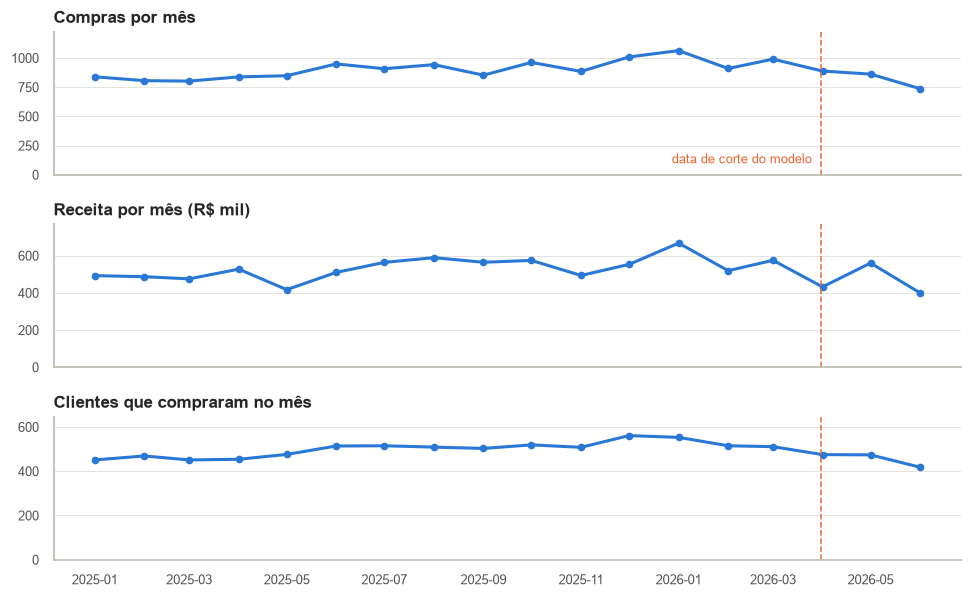

In [9]:
mensal = ler("""
    SELECT d.ano, d.mes, min(d.data) AS inicio, count(*) AS compras, sum(f.valor) AS receita,
           count(DISTINCT f.cliente_id) AS clientes_ativos
    FROM dw.fato_compras f JOIN dw.dim_data d ON d.data = f.data_compra
    GROUP BY d.ano, d.mes ORDER BY d.ano, d.mes
""")
mensal['inicio'] = pd.to_datetime(mensal['inicio']).dt.to_period('M').dt.to_timestamp()

fig, eixos = plt.subplots(3, 1, figsize=(9, 5.6), sharex=True)
for ax, coluna, titulo, escala in [(eixos[0], 'compras', 'Compras por mês', 1), (eixos[1], 'receita', 'Receita por mês (R$ mil)', 1000),
                                   (eixos[2], 'clientes_ativos', 'Clientes que compraram no mês', 1)]:
    ax.plot(mensal['inicio'], mensal[coluna] / escala, color=AZUL, linewidth=2, marker='o', markersize=4)
    ax.axvline(config.CORTE, color=LARANJA, linewidth=1, linestyle='--')
    ax.set(title=titulo, ylim=(0, mensal[coluna].max() / escala * 1.15))
    ax.grid(axis='x', visible=False)
eixos[0].annotate('data de corte do modelo', (config.CORTE, 0.08), xycoords=('data', 'axes fraction'), xytext=(-6, 0),
                  textcoords='offset points', ha='right', fontsize=8.5, color=LARANJA)
fig.tight_layout()
salvar(fig, '03_evolucao_mensal.png')

In [10]:
dias = ler("""
    SELECT d.dia_semana, d.nome_dia, count(*) AS compras, round(avg(f.valor), 2) AS ticket_medio
    FROM dw.fato_compras f JOIN dw.dim_data d ON d.data = f.data_compra
    GROUP BY 1, 2 ORDER BY 1
""")
dias['% das compras'] = 100 * dias['compras'] / dias['compras'].sum()
dias.drop(columns='dia_semana')

,nome_dia,compras,ticket_medio,% das compras
0,Segunda,2334,562.32,14.50
1,Terça,2335,600.33,14.51
2,Quarta,2261,587.11,14.05
3,Quinta,2320,569.65,14.42
4,Sexta,2260,610.14,14.04
5,Sábado,2301,579.02,14.30
6,Domingo,2281,580.66,14.17


## 4. Produtos e categorias

A margem só existe porque o catálogo (JSON) traz o custo de cada produto.

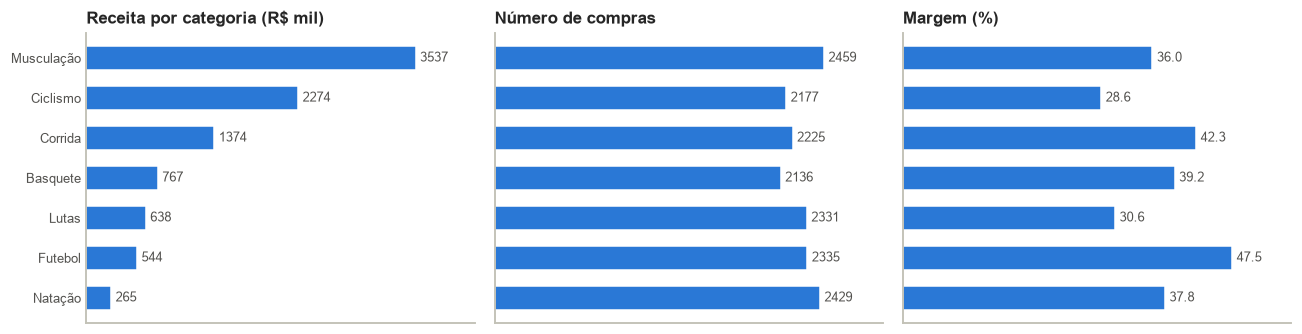

In [11]:
categorias = ler("""
    SELECT categoria, count(*) AS compras, sum(valor) AS receita, sum(margem) AS margem,
           round(100 * sum(margem) / sum(valor), 1) AS margem_pct, round(avg(valor), 2) AS ticket_medio
    FROM dw.vw_compras GROUP BY categoria ORDER BY receita
""")

fig, eixos = plt.subplots(1, 3, figsize=(12, 3.2))
for ax, coluna, titulo, fmt, escala in [(eixos[0], 'receita', 'Receita por categoria (R$ mil)', '%.0f', 1000),
                                        (eixos[1], 'compras', 'Número de compras', '%d', 1), (eixos[2], 'margem_pct', 'Margem (%)', '%.1f', 1)]:
    barras = ax.barh(categorias['categoria'], categorias[coluna] / escala, color=AZUL, height=0.6)
    rotular(ax, barras, fmt=fmt)
    ax.set(title=titulo, xlim=(0, categorias[coluna].max() / escala * 1.18))
    limpar_eixos(ax)
for ax in eixos[1:]:
    ax.set_yticklabels([])
fig.tight_layout()
salvar(fig, '04_categorias.png')

In [12]:
ler("""
    SELECT produto, categoria, count(*) AS compras, sum(quantidade) AS unidades, round(sum(valor), 2) AS receita
    FROM dw.vw_compras GROUP BY 1, 2 ORDER BY receita DESC LIMIT 5
""")

,produto,categoria,compras,unidades,receita
0,Estação de Musculação,Musculação,626,876,"2,828,515.80"
1,Bicicleta Aro 29,Ciclismo,546,743,"1,988,098.14"
2,Relógio GPS,Corrida,566,741,"890,742.86"
3,Tênis Cano Alto,Basquete,697,933,"517,396.08"
4,Banco Regulável,Musculação,609,827,"497,137.25"


## 5. Clientes

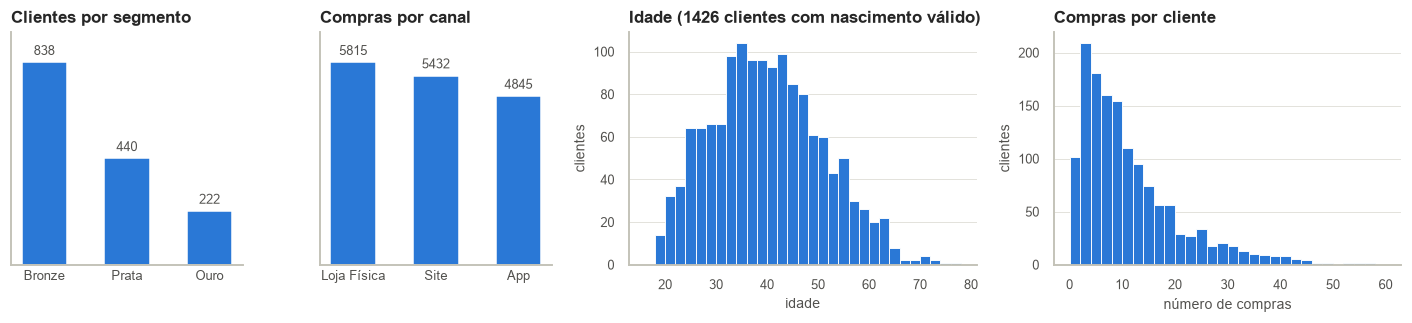

In [13]:
clientes = ler("""
    SELECT c.cliente_id, c.segmento, c.data_cadastro, c.data_nascimento, l.regiao, l.municipio, l.uf,
           count(f.id_compra) AS compras, coalesce(sum(f.valor), 0) AS total_gasto
    FROM dw.dim_cliente c
    LEFT JOIN dw.dim_localidade l USING (codigo_ibge)
    LEFT JOIN dw.fato_compras f USING (cliente_id)
    GROUP BY 1, 2, 3, 4, 5, 6, 7
""")
clientes['idade'] = (config.HOJE - pd.to_datetime(clientes['data_nascimento'])).dt.days / 365.25
canais = ler('SELECT canal, count(*) AS compras FROM dw.fato_compras GROUP BY 1').set_index('canal')['compras'].reindex(config.CANAIS)

fig, eixos = plt.subplots(1, 4, figsize=(13, 3.1), gridspec_kw={'width_ratios': [0.8, 0.8, 1.2, 1.2]})
seg = clientes['segmento'].value_counts().reindex(config.SEGMENTOS)
rotular(eixos[0], eixos[0].bar(seg.index, seg.values, color=AZUL, width=0.55))
eixos[0].set(title='Clientes por segmento', ylim=(0, seg.max() * 1.15))
rotular(eixos[1], eixos[1].bar(canais.index, canais.values, color=AZUL, width=0.55))
eixos[1].set(title='Compras por canal', ylim=(0, canais.max() * 1.15))
for ax in eixos[:2]:
    limpar_eixos(ax, 'y')
sns.histplot(clientes['idade'].dropna(), bins=range(16, 80, 2), color=AZUL, edgecolor='white', linewidth=0.6, alpha=1, ax=eixos[2])
eixos[2].set(title=f'Idade ({clientes["idade"].notna().sum()} clientes com nascimento válido)', xlabel='idade', ylabel='clientes')
sns.histplot(clientes.loc[clientes['compras'] > 0, 'compras'], bins=range(0, 61, 2), color=AZUL, edgecolor='white', linewidth=0.6, alpha=1, ax=eixos[3])
eixos[3].set(title='Compras por cliente', xlabel='número de compras', ylabel='clientes')
for ax in eixos[2:]:
    ax.grid(axis='x', visible=False)
fig.tight_layout()
salvar(fig, '05_clientes.png')

In [14]:
print(f'Clientes no cadastro: {len(clientes)} | sem nenhuma compra válida: {(clientes["compras"] == 0).sum()} | '
      f'sem nascimento válido: {clientes["idade"].isna().sum()} | sem cidade: {clientes["regiao"].isna().sum()}')
clientes.groupby('segmento')[['compras', 'total_gasto']].mean().reindex(config.SEGMENTOS).rename(
    columns={'compras': 'compras por cliente', 'total_gasto': 'gasto por cliente (R$)'})

Clientes no cadastro: 1500 | sem nenhuma compra válida: 81 | sem nascimento válido: 74 | sem cidade: 45


,compras por cliente,gasto por cliente (R$)
segmento,,
Bronze,8.35,"5,077.28"
Prata,12.00,"6,645.23"
Ouro,17.17,"10,001.41"


## 6. Localidade (API do IBGE e Kaggle)

A planilha de clientes só tem o nome da cidade e a UF. A API do IBGE transforma isso em um código de município
com estado e região, e o dataset do Kaggle acrescenta população, IDHM e PIB per capita. Sem essas duas fontes
não existiria análise por região nem por perfil de cidade.

In [15]:
cobertura = ler("""
    SELECT count(*) AS municipios, count(idhm) AS com_idhm, count(populacao) AS com_populacao, count(pib_per_capita) AS com_pib,
           (SELECT count(DISTINCT codigo_ibge) FROM dw.dim_cliente) AS municipios_com_clientes
    FROM dw.dim_localidade
""")
cobertura

,municipios,com_idhm,com_populacao,com_pib,municipios_com_clientes
0,5571,5551,5557,5557,30


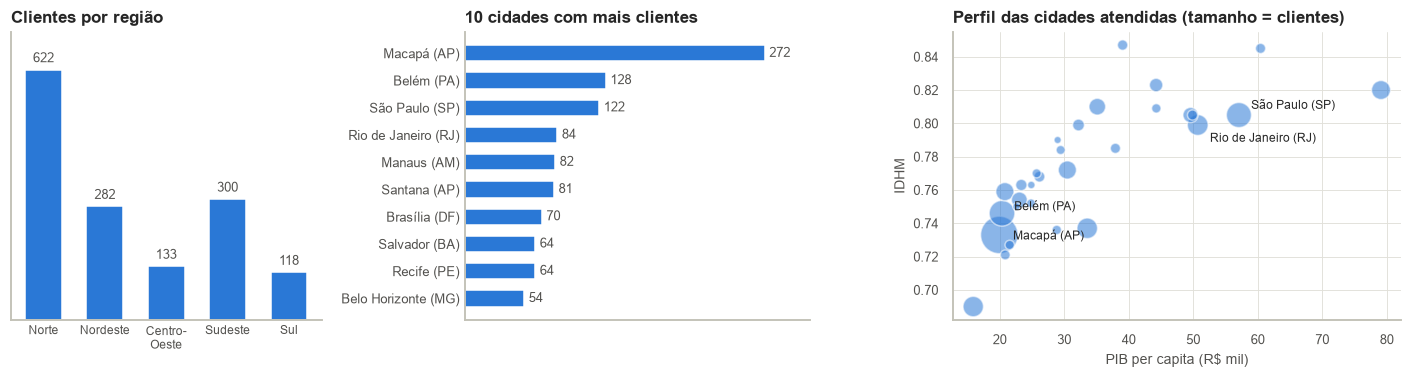

In [16]:
cidades = ler("""
    SELECT l.municipio || ' (' || l.uf || ')' AS cidade, l.regiao, l.populacao, l.idhm, l.pib_per_capita,
           count(DISTINCT c.cliente_id) AS clientes, round(sum(f.valor), 2) AS receita
    FROM dw.dim_cliente c
    JOIN dw.dim_localidade l USING (codigo_ibge)
    LEFT JOIN dw.fato_compras f USING (cliente_id)
    GROUP BY 1, 2, 3, 4, 5 ORDER BY clientes DESC
""")
regioes = cidades.groupby('regiao')['clientes'].sum().reindex(config.REGIOES)

fig, eixos = plt.subplots(1, 3, figsize=(13, 3.6), gridspec_kw={'width_ratios': [0.9, 1, 1.3]})
rotular(eixos[0], eixos[0].bar(regioes.index.str.replace('-', '-\n'), regioes.values, color=AZUL, width=0.6))
eixos[0].set(title='Clientes por região', ylim=(0, regioes.max() * 1.15))
eixos[0].tick_params(axis='x', labelsize=8)
limpar_eixos(eixos[0], 'y')
top = cidades.head(10).iloc[::-1]
rotular(eixos[1], eixos[1].barh(top['cidade'], top['clientes'], color=AZUL, height=0.6))
eixos[1].set(title='10 cidades com mais clientes', xlim=(0, top['clientes'].max() * 1.15))
limpar_eixos(eixos[1])
eixos[2].scatter(cidades['pib_per_capita'] / 1000, cidades['idhm'], s=cidades['clientes'] * 2.2, color=AZUL, alpha=0.55, edgecolor='white')
for (_, c), desloc in zip(cidades.head(4).iterrows(), [(9, -3), (8, 2), (8, 4), (8, -11)]):
    eixos[2].annotate(c['cidade'], (c['pib_per_capita'] / 1000, c['idhm']), xytext=desloc, textcoords='offset points', fontsize=8)
eixos[2].set(title='Perfil das cidades atendidas (tamanho = clientes)', xlabel='PIB per capita (R$ mil)', ylabel='IDHM')
fig.tight_layout()
salvar(fig, '06_localidade.png')

## 7. Churn: quem abandona

**Definição.** Um cliente deu churn se **não comprou nos 90 dias depois da data de corte** (31/03/2026).
Entram na análise os clientes ativos, que compraram pelo menos uma vez nos 180 dias antes do corte.
As features usam só o que aconteceu até o corte. A tabela abaixo é montada por `src/features.py`, o mesmo
código que o pipeline usa.

Clientes ativos no corte: 999 | deram churn: 308 (30.8%) | ficaram: 691


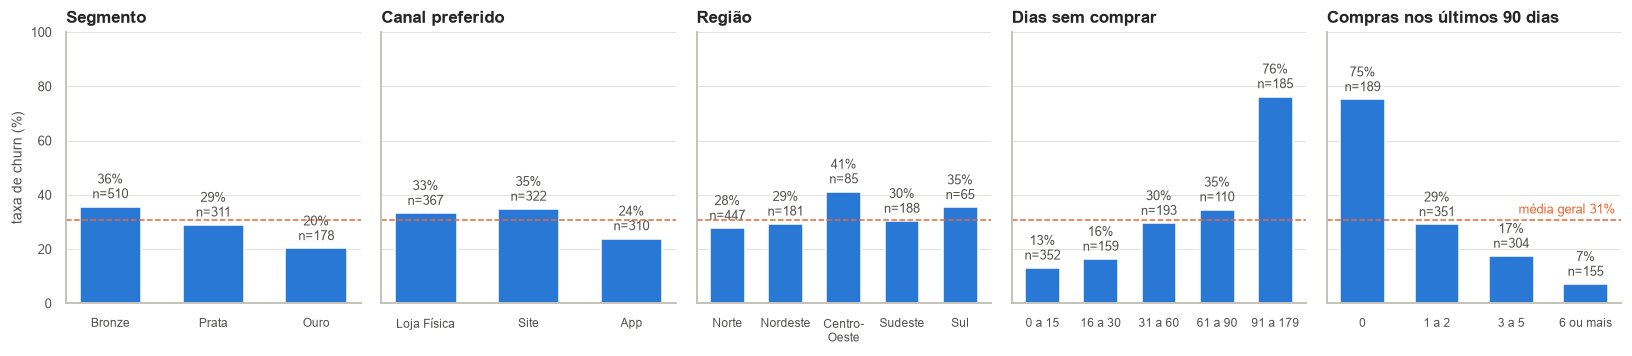

In [17]:
tab = features.criar_features(features.ler_compras(engine))
taxa = tab['churn'].mean()
print(f'Clientes ativos no corte: {len(tab)} | deram churn: {tab["churn"].sum()} ({taxa:.1%}) | ficaram: {(tab["churn"] == 0).sum()}')

tab['faixa_recencia'] = pd.cut(tab['dias_sem_comprar'], [-1, 15, 30, 60, 90, 180], labels=['0 a 15', '16 a 30', '31 a 60', '61 a 90', '91 a 179'])
tab['faixa_compras_90d'] = pd.cut(tab['qtd_compras_90d'], [-1, 0, 2, 5, 100], labels=['0', '1 a 2', '3 a 5', '6 ou mais'])
paineis = [('segmento', 'Segmento', config.SEGMENTOS), ('canal_preferido', 'Canal preferido', config.CANAIS), ('regiao', 'Região', config.REGIOES),
           ('faixa_recencia', 'Dias sem comprar', None), ('faixa_compras_90d', 'Compras nos últimos 90 dias', None)]

fig, eixos = plt.subplots(1, 5, figsize=(15, 3.4), sharey=True)
for ax, (coluna, titulo, ordem) in zip(eixos, paineis):
    grupo = tab.groupby(coluna, observed=True)['churn'].agg(['mean', 'size'])
    grupo = grupo.reindex(ordem) if ordem else grupo
    barras = ax.bar(grupo.index.astype(str).str.replace('-', '-\n'), 100 * grupo['mean'], color=AZUL, width=0.6)
    rotular(ax, barras, labels=[f'{100 * m:.0f}%\nn={n}' for m, n in zip(grupo['mean'], grupo['size'])])
    ax.axhline(100 * taxa, color=LARANJA, linewidth=1, linestyle='--')
    ax.set(title=titulo, ylim=(0, 100))
    ax.tick_params(axis='x', labelsize=8)
    ax.grid(axis='x', visible=False)
eixos[0].set_ylabel('taxa de churn (%)')
eixos[-1].annotate(f'média geral {taxa:.0%}', (0.98, 100 * taxa), xycoords=('axes fraction', 'data'), xytext=(0, 4), textcoords='offset points', ha='right', fontsize=8.5, color=LARANJA)
fig.tight_layout()
salvar(fig, '07_churn_por_grupo.png')

## 8. Correlação das features com o churn

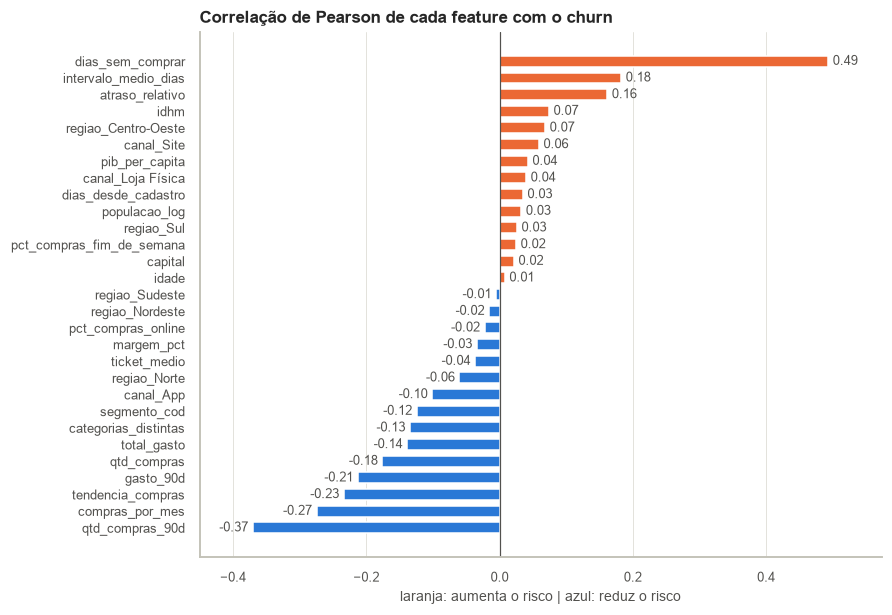

In [18]:
X, y = features.codificar(tab.drop(columns=['faixa_recencia', 'faixa_compras_90d'])), tab['churn']
corr = pd.DataFrame({'pearson': X.corrwith(y), 'spearman': X.corrwith(y, method='spearman')}).sort_values('pearson')
corr.round(3).rename_axis('feature').to_csv(config.RESULTADOS / 'correlacao_target.csv')

fig, ax = plt.subplots(figsize=(8, 6.2))
barras = ax.barh(corr.index, corr['pearson'], color=[LARANJA if v > 0 else AZUL for v in corr['pearson']], height=0.65)
rotular(ax, barras, fmt='%.2f')
ax.axvline(0, color=TEXTO, linewidth=0.8)
ax.set(title='Correlação de Pearson de cada feature com o churn', xlabel='laranja: aumenta o risco | azul: reduz o risco',
       xlim=(corr['pearson'].min() - 0.08, corr['pearson'].max() + 0.08))
ax.grid(axis='y', visible=False)
salvar(fig, '08_correlacao_target.png')

In [19]:
entre = X.corr().where(np.triu(np.ones((X.shape[1],) * 2, dtype=bool), k=1)).stack()
print('Pares de features com correlação acima de 0,8 em módulo:')
print(entre[entre.abs() > 0.8].sort_values(ascending=False).round(2).to_string())

Pares de features com correlação acima de 0,8 em módulo:
idhm                pib_per_capita       0.82
pct_compras_online  canal_Loja Física   -0.95


## 9. Achados

In [20]:
n = lambda v, casas=1: f'{v:.{casas}f}'.replace('.', ',')
mil = lambda v: f'{int(v):,}'.replace(',', '.')
compras_bruto, compras_limpo = len(st_compras), resumo.loc[0, 'linhas no dw']
por = lambda coluna: tab.groupby(coluna, observed=True)['churn'].mean()
top_cat = categorias.iloc[-1]
norte = regioes['Norte'] / regioes.sum()
reg = por('regiao').sort_values()
fortes = corr['pearson'].abs().sort_values(ascending=False).index[:3]
pares = '; '.join(f'`{a}` e `{b}` ({n(r, 2)})' for (a, b), r in entre[entre.abs() > 0.8].items())
Markdown(f"""
- **Limpeza.** Das {mil(compras_bruto)} linhas de compras que chegaram, {mil(compras_limpo)} ({n(100 * compras_limpo / compras_bruto)}%) foram para o
  modelo estrela. O cadastro tinha {len(st_clientes) - len(clientes)} linhas repetidas e ficou com {mil(len(clientes))} clientes.
- **Vendas.** {top_cat['categoria']} é a categoria de maior receita (R$ {n(top_cat['receita'] / 1e6, 2)} milhões) com ticket médio de
  R$ {mil(top_cat['ticket_medio'])}. O volume fica entre {mil(mensal['compras'].min())} e {mil(mensal['compras'].max())} compras por mês, sem sazonalidade
  forte, e as compras se distribuem igualmente pelos dias da semana.
- **Clientes.** {n(100 * norte)}% dos clientes com cidade conhecida estão no Norte, onde a loja nasceu. O segmento Ouro compra
  mais vezes e gasta mais por cliente.
- **Churn.** {n(100 * taxa)}% dos {len(tab)} clientes ativos no corte não voltaram a comprar em 90 dias. As classes são
  desbalanceadas (cerca de 1 churn para cada 2 clientes que ficam), então accuracy sozinha não serve para avaliar o modelo.
- **Quem abandona mais.** Bronze ({n(100 * por('segmento')['Bronze'], 0)}%) contra Ouro ({n(100 * por('segmento')['Ouro'], 0)}%);
  Loja Física ({n(100 * por('canal_preferido')['Loja Física'], 0)}%) contra App ({n(100 * por('canal_preferido')['App'], 0)}%).
  Entre as regiões, a taxa vai de {n(100 * reg.iloc[0], 0)}% ({reg.index[0]}) a {n(100 * reg.iloc[-1], 0)}% ({reg.index[-1]}), mas os grupos
  fora do Norte são pequenos e a diferença tem bastante ruído.
- **Sinais mais fortes.** {', '.join(f'`{f}`' for f in fortes)}. Recência e atividade recente dominam: quem está há mais de
  60 dias sem comprar tem churn de {n(100 * tab.loc[tab['dias_sem_comprar'] > 60, 'churn'].mean(), 0)}%.
- **Redundância.** Pares de features com correlação acima de 0,8 em módulo: {pares}. Os indicadores de cidade
  variam pouco porque são só {cobertura['municipios_com_clientes'][0]} cidades.
""")


- **Limpeza.** Das 17.592 linhas de compras que chegaram, 16.092 (91,5%) foram para o
  modelo estrela. O cadastro tinha 45 linhas repetidas e ficou com 1.500 clientes.
- **Vendas.** Musculação é a categoria de maior receita (R$ 3,54 milhões) com ticket médio de
  R$ 1.438. O volume fica entre 737 e 1.063 compras por mês, sem sazonalidade
  forte, e as compras se distribuem igualmente pelos dias da semana.
- **Clientes.** 42,7% dos clientes com cidade conhecida estão no Norte, onde a loja nasceu. O segmento Ouro compra
  mais vezes e gasta mais por cliente.
- **Churn.** 30,8% dos 999 clientes ativos no corte não voltaram a comprar em 90 dias. As classes são
  desbalanceadas (cerca de 1 churn para cada 2 clientes que ficam), então accuracy sozinha não serve para avaliar o modelo.
- **Quem abandona mais.** Bronze (36%) contra Ouro (20%);
  Loja Física (33%) contra App (24%).
  Entre as regiões, a taxa vai de 28% (Norte) a 41% (Centro-Oeste), mas os grupos
  fora do Norte são pequenos e a diferença tem bastante ruído.
- **Sinais mais fortes.** `dias_sem_comprar`, `qtd_compras_90d`, `compras_por_mes`. Recência e atividade recente dominam: quem está há mais de
  60 dias sem comprar tem churn de 61%.
- **Redundância.** Pares de features com correlação acima de 0,8 em módulo: `idhm` e `pib_per_capita` (0,82); `pct_compras_online` e `canal_Loja Física` (-0,95). Os indicadores de cidade
  variam pouco porque são só 30 cidades.
